<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


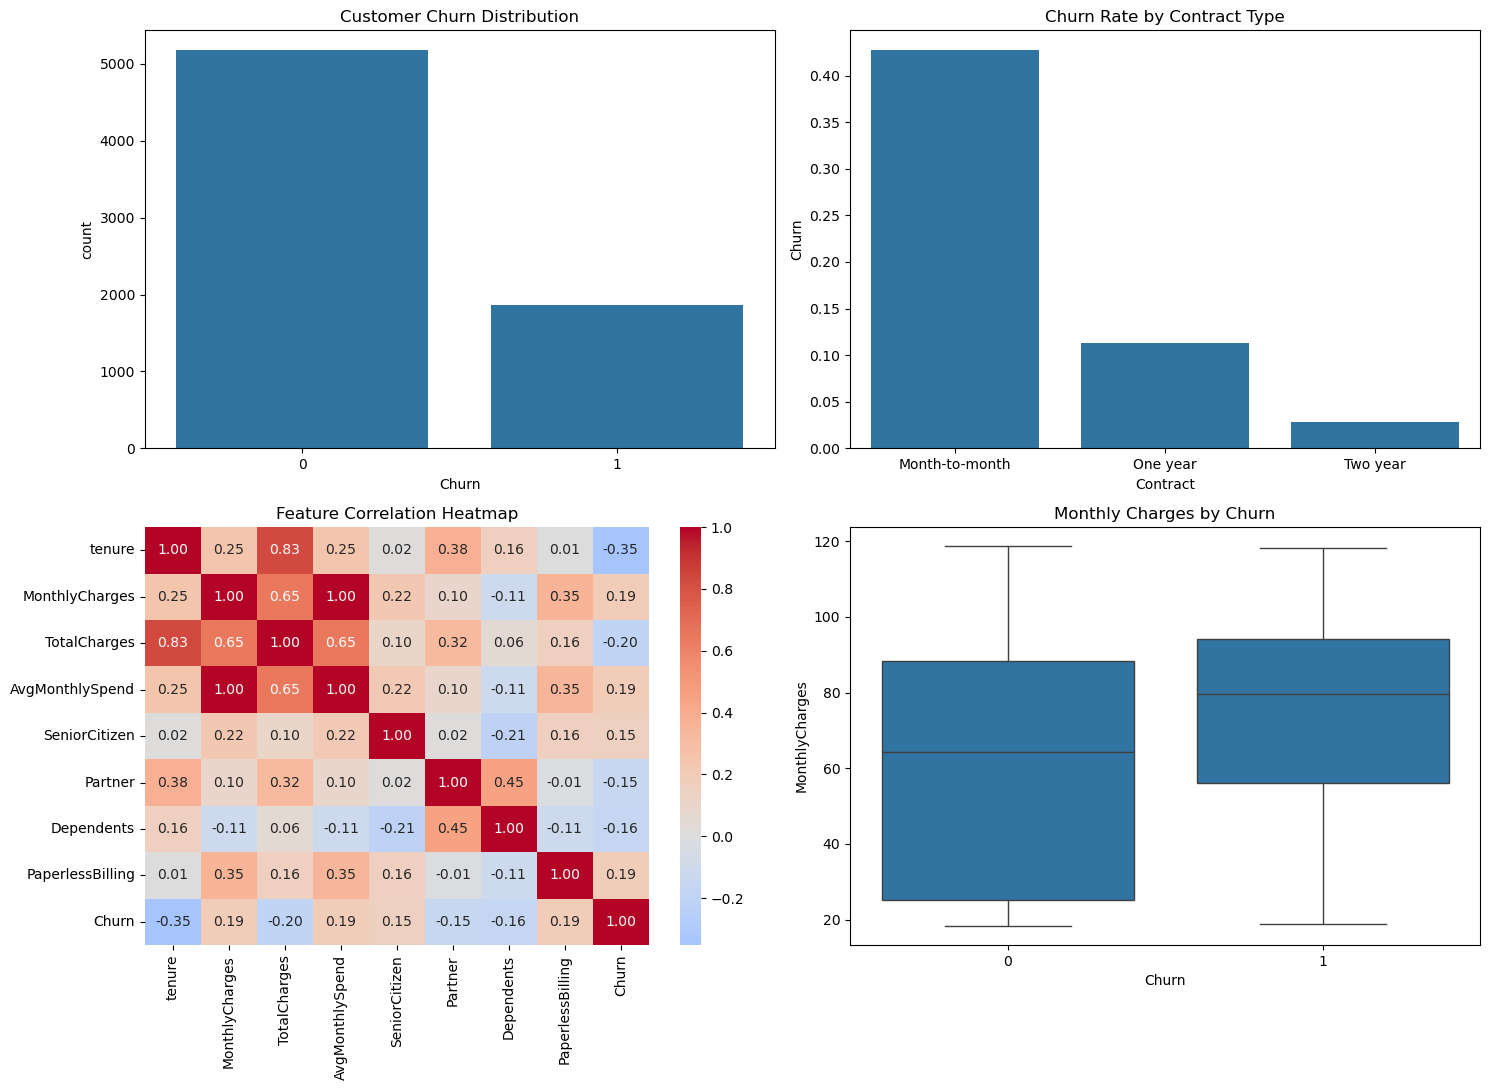

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data Understanding
df_telco = pd.read_csv('Telcom Customer Dataset.csv')
print(df_telco.info())
print(df_telco.describe())

# 2. Data Cleaning
df_telco['TotalCharges'] = pd.to_numeric(df_telco['TotalCharges'], errors='coerce')
df_telco['TotalCharges'] = df_telco['TotalCharges'].fillna(0)  # All 11 nulls have tenure == 0

# 3. Feature Engineering
bins = [-1, 12, 24, 48, 60, np.inf]
labels = ['0-12 months', '13-24 months', '25-48 months', '49-60 months', '61+ months']
df_telco['TenureGroup'] = pd.cut(df_telco['tenure'], bins=bins, labels=labels)

df_telco['AvgMonthlySpend'] = np.where(
    df_telco['tenure'] > 0,
    df_telco['TotalCharges'] / df_telco['tenure'],
    df_telco['MonthlyCharges']
)

binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    df_telco[col] = df_telco[col].map({'Yes': 1, 'No': 0})

ohe_cols = [
    'Contract', 'InternetService', 'PaymentMethod', 'MultipleLines',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
    'StreamingTV', 'StreamingMovies', 'gender'
]
df_telco_encoded = pd.get_dummies(df_telco, columns=ohe_cols, dtype=int)
df_telco_encoded.to_csv('cleaned.csv', index=False)

# 4. EDA & Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
sns.countplot(data=df_telco, x='Churn', ax=axes[0, 0])
axes[0, 0].set_title('Customer Churn Distribution')

sns.barplot(data=df_telco, x='Contract', y='Churn', order=['Month-to-month', 'One year', 'Two year'], errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title('Churn Rate by Contract Type')

corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend', 'SeniorCitizen', 'Partner', 'Dependents', 'PaperlessBilling', 'Churn']
sns.heatmap(df_telco[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 0])
axes[1, 0].set_title('Feature Correlation Heatmap')

sns.boxplot(data=df_telco, x='Churn', y='MonthlyCharges', ax=axes[1, 1])
axes[1, 1].set_title('Monthly Charges by Churn')

plt.tight_layout()
plt.savefig('task3_telco_eda.png', dpi=200)
plt.show()